<a href="https://colab.research.google.com/github/Saurabhtaur1212/ML57/blob/main/Collaborative_Filtering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)


In [2]:
ratings = pd.DataFrame(
    {
        "Inception": [5, 5, 4, 1, 2, np.nan, 5, 2],
        "Interstellar": [5, 4, 5, 2, 2, np.nan, 5, 1],
        "The Matrix": [4, 5, 5, 1, 2, 2, 4, 1],
        "Titanic": [1, 2, 1, 5, 5, 4, 2, 5],
        "The Notebook": [1, 1, 2, 5, 4, 5, 1, 5],
        "Avengers": [4, 5, 4, 2, 3, 2, 5, 2],
        "Toy Story": [3, 4, 3, 2, 4, 5, 4, 3],
        "Frozen": [2, 2, 1, 4, 5, 5, 2, 4]
    },
    index=[
        "User_1", "User_2", "User_3", "User_4",
        "User_5", "User_6", "User_7", "User_8"
    ]
)

print("User-Item Matrix:")
display(ratings)


User-Item Matrix:


,Inception,Interstellar,The Matrix,Titanic,The Notebook,Avengers,Toy Story,Frozen
User_1,5.0,5.0,4,1,1,4,3,2
User_2,5.0,4.0,5,2,1,5,4,2
User_3,4.0,5.0,5,1,2,4,3,1
User_4,1.0,2.0,1,5,5,2,2,4
User_5,2.0,2.0,2,5,4,3,4,5
User_6,NaN,NaN,2,4,5,2,5,5
User_7,5.0,5.0,4,2,1,5,4,2
User_8,2.0,1.0,1,5,5,2,3,4


In [3]:
print("Number of users :", ratings.shape[0])
print("Number of items :", ratings.shape[1])
print("Number of ratings:", ratings.notna().sum().sum())

sparsity = 1 - (
    ratings.notna().sum().sum()
    / ratings.size
)

print("Matrix sparsity:", round(sparsity, 4))

print("\nRatings per user:")
display(ratings.notna().sum(axis=1))

print("\nRatings per item:")
display(ratings.notna().sum(axis=0))

Number of users : 8
Number of items : 8
Number of ratings: 62
Matrix sparsity: 0.0312

Ratings per user:


,0
User_1,8
User_2,8
User_3,8
User_4,8
User_5,8
User_6,6
User_7,8
User_8,8



Ratings per item:


,0
Inception,7
Interstellar,7
The Matrix,8
Titanic,8
The Notebook,8
Avengers,8
Toy Story,8
Frozen,8


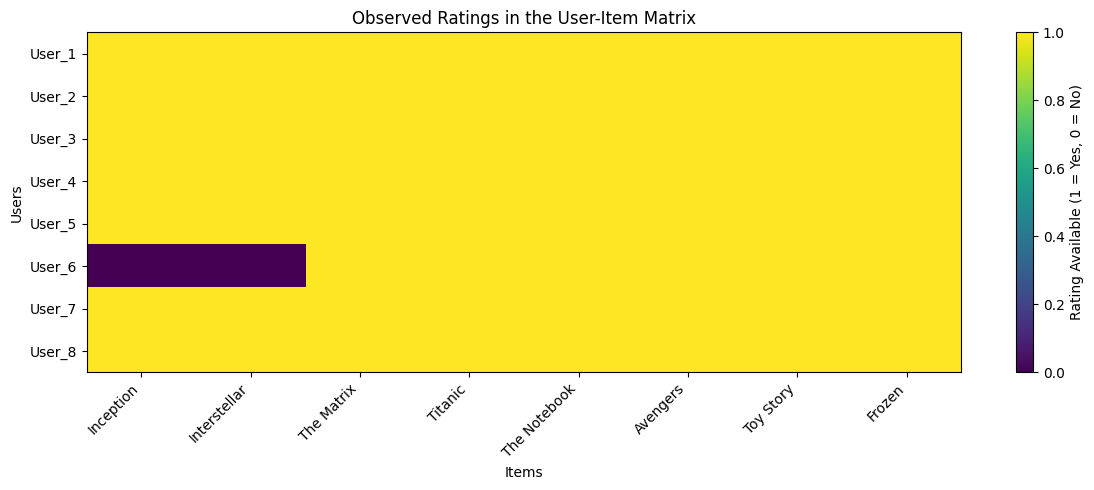

In [4]:
plt.figure(figsize=(12, 5))

plt.imshow(
    ratings.notna(),
    aspect="auto"
)

plt.xticks(
    range(len(ratings.columns)),
    ratings.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(ratings.index)),
    ratings.index
)

plt.xlabel("Items")
plt.ylabel("Users")
plt.title("Observed Ratings in the User-Item Matrix")
plt.colorbar(label="Rating Available (1 = Yes, 0 = No)")
plt.tight_layout()
plt.show()


# PART-A : User Based Collaborative filtering

In [5]:
user_matrix_zero = ratings.fillna(0)

user_cosine = cosine_similarity(user_matrix_zero)

user_cosine_df = pd.DataFrame(
    user_cosine,
    index=ratings.index,
    columns=ratings.index
)

display(user_cosine_df.round(3))


,User_1,User_2,User_3,User_4,User_5,User_6,User_7,User_8
User_1,1.000,0.980,0.979,0.579,0.710,0.510,0.990,0.595
User_2,0.980,1.000,0.971,0.612,0.759,0.588,0.991,0.645
User_3,0.979,0.971,1.000,0.590,0.700,0.531,0.971,0.595
User_4,0.579,0.612,0.590,1.000,0.958,0.910,0.623,0.982
User_5,0.710,0.759,0.700,0.958,1.000,0.941,0.759,0.973
User_6,0.510,0.588,0.531,0.910,0.941,1.000,0.569,0.938
User_7,0.990,0.991,0.971,0.623,0.759,0.569,1.000,0.645
User_8,0.595,0.645,0.595,0.982,0.973,0.938,0.645,1.000


In [6]:
user_pearson = ratings.T.corr(
    min_periods=2
)

display(user_pearson.round(3))

,User_1,User_2,User_3,User_4,User_5,User_6,User_7,User_8
User_1,1.000,0.895,0.894,-0.925,-0.893,-0.739,0.949,-0.947
User_2,0.895,1.000,0.841,-0.961,-0.787,-0.776,0.944,-0.895
User_3,0.894,0.841,1.000,-0.873,-0.960,-0.777,0.841,-0.947
User_4,-0.925,-0.961,-0.873,1.000,0.838,0.644,-0.907,0.925
User_5,-0.893,-0.787,-0.960,0.838,1.000,0.794,-0.787,0.893
User_6,-0.739,-0.776,-0.777,0.644,0.794,1.000,-0.702,0.777
User_7,0.949,0.944,0.841,-0.907,-0.787,-0.702,1.000,-0.895
User_8,-0.947,-0.895,-0.947,0.925,0.893,0.777,-0.895,1.000


In [7]:
target_user = "User_1"

similar_users = (
    user_cosine_df[target_user]
    .drop(target_user)
    .sort_values(ascending=False)
)

print("Users most similar to", target_user)
display(similar_users.to_frame("Cosine Similarity"))

Users most similar to User_1


,Cosine Similarity
User_7,0.989862
User_2,0.980434
User_3,0.979381
User_5,0.710320
User_8,0.594701
User_4,0.578948
User_6,0.510231


In [8]:
def user_based_recommend(
    ratings_matrix,
    target_user,
    similarity_matrix,
    top_n=3,
    min_similarity=0
):
    user_similarities = similarity_matrix[target_user].drop(target_user)

    recommendations = {}

    unseen_items = ratings_matrix.columns[
        ratings_matrix.loc[target_user].isna()
    ]

    for item in unseen_items:
        numerator = 0.0
        denominator = 0.0

        for other_user, similarity in user_similarities.items():
            rating = ratings_matrix.loc[other_user, item]

            if pd.notna(rating) and similarity > min_similarity:
                numerator += similarity * rating
                denominator += abs(similarity)

        if denominator > 0:
            recommendations[item] = numerator / denominator

    return (
        pd.Series(recommendations)
        .sort_values(ascending=False)
        .head(top_n)
    )


user_recommendations = user_based_recommend(
    ratings,
    target_user,
    user_cosine_df,
    top_n=3
)

print("Top-N User-Based Recommendations:")
display(
    user_recommendations.to_frame("Predicted Score")
)

Top-N User-Based Recommendations:


,Predicted Score


In [10]:
user_pearson_recommendations = user_based_recommend(
    ratings,
    target_user,
    user_pearson,
    top_n=3,
    min_similarity=0
)

print("Top-N Recommendations using Pearson Similarity:")
display(
    user_pearson_recommendations.to_frame("Predicted Score")
)

Top-N Recommendations using Pearson Similarity:


,Predicted Score


# PART-B: Item-Based Collaborative Filtering

In [11]:
item_matrix_zero = ratings.fillna(0).T

item_cosine = cosine_similarity(item_matrix_zero)

item_cosine_df = pd.DataFrame(
    item_cosine,
    index=ratings.columns,
    columns=ratings.columns
)

display(item_cosine_df.round(3))

,Inception,Interstellar,The Matrix,Titanic,The Notebook,Avengers,Toy Story,Frozen
Inception,1.000,0.980,0.959,0.537,0.465,0.966,0.814,0.575
Interstellar,0.980,1.000,0.959,0.527,0.475,0.956,0.794,0.564
The Matrix,0.959,0.959,1.000,0.571,0.537,0.976,0.879,0.631
Titanic,0.537,0.527,0.571,1.000,0.975,0.696,0.849,0.980
The Notebook,0.465,0.475,0.537,0.975,1.000,0.637,0.822,0.964
Avengers,0.966,0.956,0.976,0.696,0.637,1.000,0.928,0.738
Toy Story,0.814,0.794,0.879,0.849,0.822,0.928,1.000,0.905
Frozen,0.575,0.564,0.631,0.980,0.964,0.738,0.905,1.000


In [12]:
item_pearson = ratings.corr(
    min_periods=2
)

display(item_pearson.round(3))

,Inception,Interstellar,The Matrix,Titanic,The Notebook,Avengers,Toy Story,Frozen
Inception,1.000,0.887,0.907,-0.912,-0.983,0.937,0.532,-0.833
Interstellar,0.887,1.000,0.907,-0.962,-0.931,0.860,0.275,-0.899
The Matrix,0.907,0.907,1.000,-0.935,-0.921,0.908,0.183,-0.871
Titanic,-0.912,-0.962,-0.935,1.000,0.902,-0.812,-0.043,0.910
The Notebook,-0.983,-0.931,-0.921,0.902,1.000,-0.967,-0.080,0.859
Avengers,0.937,0.860,0.908,-0.812,-0.967,1.000,0.178,-0.804
Toy Story,0.532,0.275,0.183,-0.043,-0.080,0.178,1.000,0.248
Frozen,-0.833,-0.899,-0.871,0.910,0.859,-0.804,0.248,1.000


In [13]:
target_ratings = ratings.loc[target_user].dropna().sort_values(
    ascending=False
)

print("Items rated by", target_user)
display(target_ratings.to_frame("Rating"))

print("\nItems similar to highly rated items:")

for item in target_ratings.head(3).index:
    print(f"\nBased on: {item}")
    display(
        item_cosine_df[item]
        .drop(item)
        .sort_values(ascending=False)
        .head(3)
        .to_frame("Cosine Similarity")
    )

Items rated by User_1


,Rating
Inception,5.0
Interstellar,5.0
The Matrix,4.0
Avengers,4.0
Toy Story,3.0
Frozen,2.0
Titanic,1.0
The Notebook,1.0



Items similar to highly rated items:

Based on: Inception


,Cosine Similarity
Interstellar,0.980000
Avengers,0.965623
The Matrix,0.959166



Based on: Interstellar


,Cosine Similarity
Inception,0.980000
The Matrix,0.959166
Avengers,0.955769



Based on: The Matrix


,Cosine Similarity
Avengers,0.975913
Interstellar,0.959166
Inception,0.959166


In [14]:
def item_based_recommend(
    ratings_matrix,
    target_user,
    item_similarity,
    top_n=3,
    min_similarity=0
):
    user_ratings = ratings_matrix.loc[target_user]

    rated_items = user_ratings.dropna()
    unseen_items = user_ratings[user_ratings.isna()].index

    recommendations = {}

    for item in unseen_items:
        numerator = 0.0
        denominator = 0.0

        for rated_item, rating in rated_items.items():
            similarity = item_similarity.loc[item, rated_item]

            if similarity > min_similarity:
                numerator += similarity * rating
                denominator += abs(similarity)

        if denominator > 0:
            recommendations[item] = numerator / denominator

    return (
        pd.Series(recommendations)
        .sort_values(ascending=False)
        .head(top_n)
    )


item_recommendations = item_based_recommend(
    ratings,
    target_user,
    item_cosine_df,
    top_n=3
)

print("Top-N Item-Based Recommendations:")
display(
    item_recommendations.to_frame("Predicted Score")
)


Top-N Item-Based Recommendations:


,Predicted Score


In [15]:
item_pearson_recommendations = item_based_recommend(
    ratings,
    target_user,
    item_pearson,
    top_n=3,
    min_similarity=0
)

print("Top-N Item-Based Recommendations using Pearson Similarity:")
display(
    item_pearson_recommendations.to_frame("Predicted Score")
)

Top-N Item-Based Recommendations using Pearson Similarity:


,Predicted Score


In [16]:
comparison_recommendations = pd.DataFrame({
    "User-Based (Cosine)": user_recommendations,
    "User-Based (Pearson)": user_pearson_recommendations,
    "Item-Based (Cosine)": item_recommendations,
    "Item-Based (Pearson)": item_pearson_recommendations
})

display(comparison_recommendations.round(3))

,User-Based (Cosine),User-Based (Pearson),Item-Based (Cosine),Item-Based (Pearson)


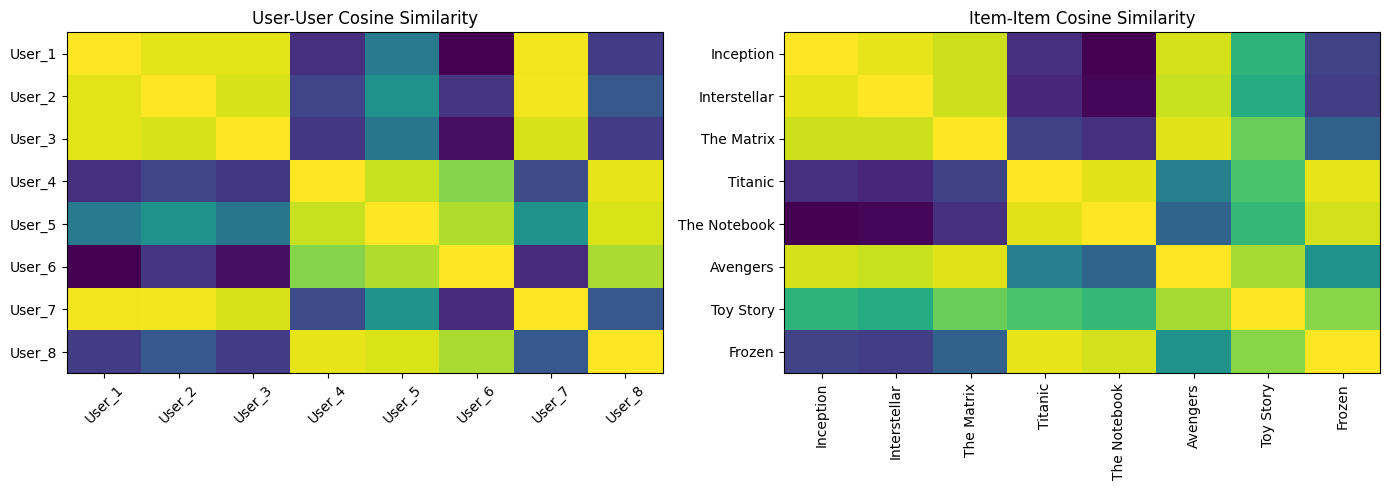

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].imshow(
    user_cosine_df,
    aspect="auto"
)

axes[0].set_title("User-User Cosine Similarity")
axes[0].set_xticks(range(len(ratings.index)))
axes[0].set_xticklabels(ratings.index, rotation=45)
axes[0].set_yticks(range(len(ratings.index)))
axes[0].set_yticklabels(ratings.index)

axes[1].imshow(
    item_cosine_df,
    aspect="auto"
)

axes[1].set_title("Item-Item Cosine Similarity")
axes[1].set_xticks(range(len(ratings.columns)))
axes[1].set_xticklabels(ratings.columns, rotation=90)
axes[1].set_yticks(range(len(ratings.columns)))
axes[1].set_yticklabels(ratings.columns)

plt.tight_layout()
plt.show()

#PART-A: Simple Evaluation

In [18]:
# Create a copy and hide one known rating for User_1.
evaluation_ratings = ratings.copy()

known_items = evaluation_ratings.loc[target_user].dropna().index

# Select a rating with a value of at least 4 when possible.
candidate_items = [
    item for item in known_items
    if evaluation_ratings.loc[target_user, item] >= 4
]

held_out_item = candidate_items[0]
held_out_rating = evaluation_ratings.loc[target_user, held_out_item]

evaluation_ratings.loc[target_user, held_out_item] = np.nan

print("Held-out item :", held_out_item)
print("Actual rating :", held_out_rating)


Held-out item : Inception
Actual rating : 5.0


In [19]:
# Recalculate user-based similarity after hiding the rating.
evaluation_user_similarity = pd.DataFrame(
    cosine_similarity(evaluation_ratings.fillna(0)),
    index=evaluation_ratings.index,
    columns=evaluation_ratings.index
)

user_eval_scores = user_based_recommend(
    evaluation_ratings,
    target_user,
    evaluation_user_similarity,
    top_n=len(evaluation_ratings.columns)
)

if held_out_item in user_eval_scores.index:
    predicted_rating = user_eval_scores.loc[held_out_item]
    print("Predicted rating for held-out item:",
          round(predicted_rating, 3))
    print("Actual rating:",
          held_out_rating)
    print(
        "Absolute error:",
        round(abs(predicted_rating - held_out_rating), 3)
    )
else:
    print("The held-out item could not be predicted from available neighbors.")


Predicted rating for held-out item: 3.42
Actual rating: 5.0
Absolute error: 1.58
